# Laboratorio 6: Evaluación, toma de decisiones y ajuste de modelos

En este laboratorio vamos a terminar de trabajar con el dataset de SCADA de la turbina aerogeneradora.

Para ello, vamos a dividir el laboratorio en dos partes.

1.   Evaluación del modelo para la toma de decisiones y definición de umbrales de clasificación

Continuaremos el proceso que hemos estado siguiendo en los anteriores para clasificar cada uno de los 5 errores presentes en nuestro dataset.

En este sentido, estudiaremos como los umbrales de clasificación pueden ayudarnos a optimizar el rendimiento y favorecer que no se incurran en determinados fallos. Esto es especialmente relevante para definir la forma en la que se toma esta decisión.

A su vez, usaremos la matriz de confusión para medir el equilibrio y la precisión de nuestras predicciones de clasificación, así como visualizar el porcentaje total de veces que se pronostica cada clase.


2.   Ajuste del modelo para detección multiclase

En la segunda parte del laboratorio vamos a retomar los datos iniciales sin el procesamiento que hemos estado realizando hasta ahora y sin considerar las ventanas temporales definidas (de 24, 28 y 72h). Por lo tanto, ahora vamos a crear un modelo capaz de detectar la aparición de algún error en un instante determinado. Al ser un problema mucho más complejo, vamos a estudiar el ajuste de parámetros y las técnicas de aumento de datos para mejorar el rendimiento del problema




In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime,timedelta
from bisect import *
from collections import defaultdict
import random
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from copy import deepcopy
import itertools
from random import shuffle


from sklearn.metrics import *
from sklearn.model_selection import *
from sklearn.linear_model import LogisticRegression     as LOG
from sklearn.ensemble import RandomForestClassifier     as RFC
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.neural_network import MLPClassifier        as MLC

from .over_sampling import SMOTE
from imblearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay,precision_recall_curve, auc
from collections import defaultdict
import missingno as msno

%matplotlib inline

#Garantizar la repetibilidad en nuestros métodos no deterministas
random.seed(7654)

#Suprimir warnings
warnings.filterwarnings("ignore")




---

## 1. Evaluación del modelo para la toma de decisiones

Como se ha introducido, esta primera parte es continuista con el trabajo de los laboratorios previos y, por tanto, vamos a emplear las predicciones y probabilidades obtenidas  en ellos.


1. Comenzamos importando los archivos necesarios, en este caso, las predicciones realizadas y sus valores de probabilidad y los datos de entrada X y salida Y.

En este caso, para tener un ejemplo que permita comprender mejor el comportamiento de los diferentes umbrales de clasificación, se han modificado los parámetros de entrenamiento del laboratorio anterior (laboratorio 5) de forma que se ha conseguido, de manera consciente, obtener resultados más variados y un umbral mayor de probabilidad.

A este respecto, en este caso los resultados han sido obtenidos con el clasificador Gradien Boosting y entrenando modelos con un menor tamaño de manera que se evite el overfitting.



In [7]:
LOCALFILE_CLASS = './data/class_predictions.csv'
dataframe_class_predictions  = pd.read_csv(LOCALFILE_CLASS)
dataframe_class_predictions['DateTime'] = pd.to_datetime(dataframe_class_predictions['DateTime'])
dataframe_class_predictions = dataframe_class_predictions.sort_values('DateTime')

In [8]:
LOCALFILE_PROB = './data/probability_predictions.csv'
dataframe_prob_predictions  = pd.read_csv(LOCALFILE_PROB)
dataframe_prob_predictions['DateTime'] = pd.to_datetime(dataframe_prob_predictions['DateTime'])
dataframe_prob_predictions = dataframe_prob_predictions.sort_values('DateTime')

In [9]:

LOCALFILE_OUTCOMES = './data/outcomes_bool.csv'
dataframe_outcomes = pd.read_csv(LOCALFILE_OUTCOMES)
dataframe_outcomes['DateTime'] = pd.to_datetime(dataframe_outcomes['DateTime'])
dataframe_outcomes = dataframe_outcomes.sort_values('DateTime')

In [10]:
LOCALFILE_FAULTS = './data/fault_data.csv'
dataframe_faults = pd.read_csv(LOCALFILE_FAULTS)
dataframe_faults['DateTime'] = pd.to_datetime(dataframe_faults['DateTime'])
dataframe_faults = dataframe_faults.sort_values('DateTime')

2. Vamos a continuar trabajando con la ventana de 72h. Por ello, extraemos las variables de outcomes de interés

In [11]:
YVarsList   = list(dataframe_outcomes.columns)[1:]

YVars24 = [a for a in YVarsList if '_24' in a]
YVars48 = [a for a in YVarsList if '_48' in a]
YVars72 = [a for a in YVarsList if '_72' in a]

#Asignamos YVars a las variables de la ventana de 72 horas
YVars = YVars72

3. Ahora vamos a filtrarlo a un determinado rango temporal, en este caso entre el 1/06/2014 y el 20/1/2015


In [12]:
dataframe_prob_predictions2 = deepcopy(dataframe_prob_predictions)

XVar = 'DateTime'
dt1  = datetime(2014,6,1)
dt2  = datetime(2015,1,20)

DTs  = list(dataframe_prob_predictions2['DateTime'])
MinI = bisect_left(DTs,dt1)
MaxI = bisect_right(DTs,dt2)
dataframe_prob_predictions2  = dataframe_prob_predictions2.iloc[MinI:MaxI-1]

4. Definimos un método de apoyo para producir fallos en un intervalo de tiempo determinado. Este código devuelve el subconjunto de fallos dentro de ese intervalo, basado en un rango de fechas y un tipo específico de fallo

In [13]:
def GetFaults(MinDT,MaxDT,Fault):
    DTs = list(dataframe_faults['DateTime'])
    MinI = bisect_left(DTs,MinDT)
    MaxI = bisect_right(DTs,MaxDT)
    dataframe_faults2 = dataframe_faults.iloc[MinI:MaxI-1]
    if len(dataframe_faults2)<1: return []
    dataframe_faults2 = dataframe_faults2[dataframe_faults2['Fault']==Fault]
    if len(dataframe_faults2)<1: return []
    return list(dataframe_faults2['DateTime'])


5. Ahora vamos a comparar visualmente los datos de los resultados reales con los de las probabilidades obtenidas para cada clasificación

Este código compara el rendimiento predictivo de nuestras predicciones a 72 horas con los datos reales agregados de la variable de resultado de la misma ventana. Podemos interpretar el rendimiento del modelo identificando picos en nuestras predicciones (la línea azul) frente a los fallos reales (las líneas rojas).



AF_72
DateTime Range:  2014-06-01 00:00:00 to 2015-01-20 00:00:00


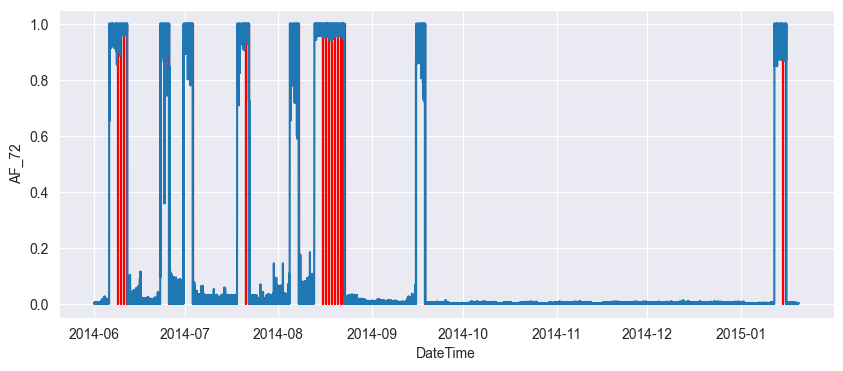

EF_72
DateTime Range:  2014-06-01 00:00:00 to 2015-01-20 00:00:00


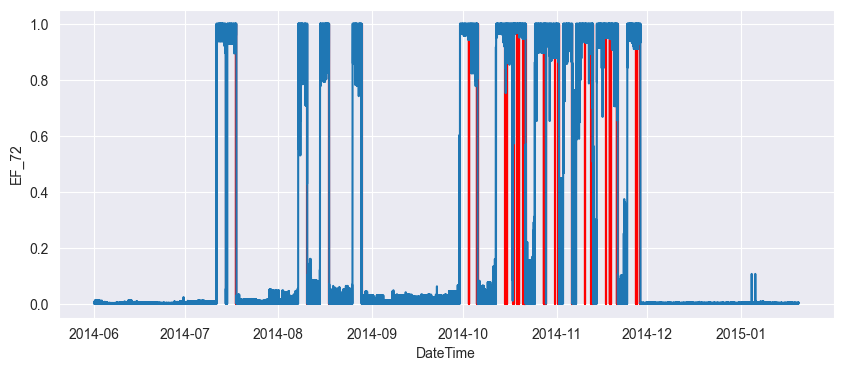

FF_72
DateTime Range:  2014-06-01 00:00:00 to 2015-01-20 00:00:00


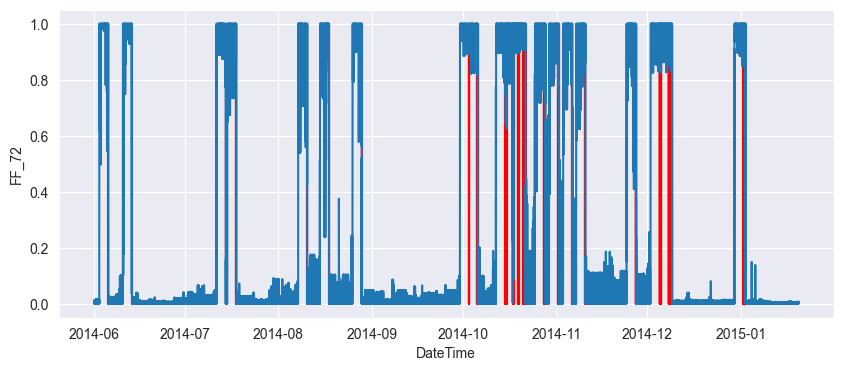

GF_72
DateTime Range:  2014-06-01 00:00:00 to 2015-01-20 00:00:00


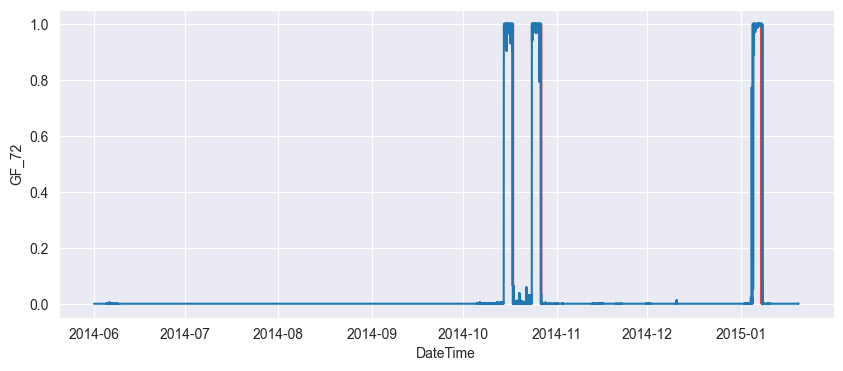

MF_72
DateTime Range:  2014-06-01 00:00:00 to 2015-01-20 00:00:00


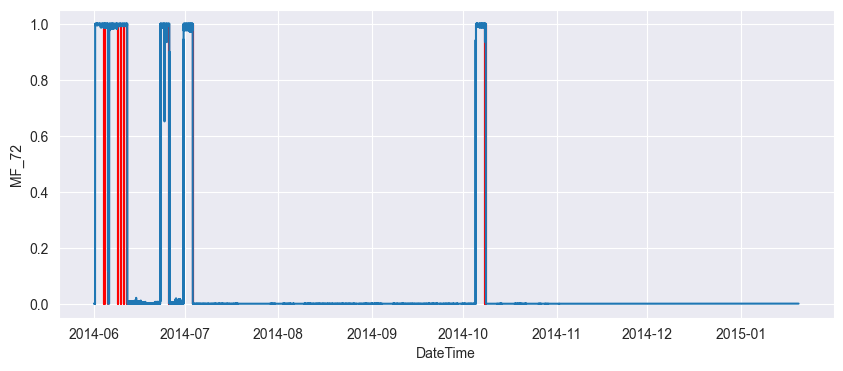

In [44]:
for YVar in YVars:
    print(YVar)
    print('DateTime Range: ',dt1,'to',dt2)     # Imprime el rango de fechas que se está utilizando para esta iteración
    sns.set_style("darkgrid")
    plt.figure(figsize=(10, 4))

    # Llama a la función GetFaults para obtener los fallos en el rango de fechas `dt1` a `dt2`
    # Filtra los fallos que coinciden con los dos primeros caracteres de `YVar` (que contienen el numbre del fallo())
    faults = GetFaults(dt1,dt2,YVar[:2])
    YVals = [0.0,1.0]
    for dt in faults:
        XVals = [dt,dt]
        plt.plot(XVals,YVals,color='r')

    XVals = dataframe_prob_predictions2[XVar]
    YVals = dataframe_prob_predictions2[YVar]

    plt.plot(XVals,YVals)

    adf = plt.gca().get_xaxis().get_major_formatter()
    adf.scaled[1.0] = '%m-%d'
    plt.ylabel(YVar)
    plt.xlabel(XVar)
    plt.ylim([-0.05,1.05])
    plt.show()


Podemos observar cómo se detectan errores para cada pico de la gráfica, lo que nos indica que, con la subida de la probabilidad a partir de determinado umbral, estas probabilidades se convierten en clasificaciones de errores.

Sin embargo, aunque este tipo de representaciones resultan útiles para ver de manera visual cómo se comportan los modelos, no nos dan una percepción cuantitativa de como de acertados son en sus predicciones.

A este respecto, en cambio, las matrices de confusión nos ofrecen una representación más nutrida de cómo se comporta realmente un modelo




----

## Matriz de confusión

Cuando se intenta clasificar (predecir) una variable booleana, puede haber 4 resultados diferentes para una predicción.

En este caso, estamos prediciendo la existencia de un suceso (un fallo). En consecuencia, estamos prediciendo si se produce o no un suceso para una observación determinada.

Por lo tanto, el modelo puede ser "correcto" de 2 formas e "incorrecto" de 2 formas.

Formas en que el modelo puede ser correcto:

* Predecir correctamente que ocurre un suceso: "Verdadero positivo" (TP)
* Predecir correctamente que no ocurre ningún suceso: "Verdadero Negativo" (TN)

Formas en que el modelo puede equivocarse:

* Predecir incorrectamente un suceso: "Falso positivo (FP)
* Predecir incorrectamente que no se produce ningún suceso: "Falso negativo (FN)

Estos resultados pueden organizarse en una matriz para analizar el rendimiento de un clasificador ML. Esto se denomina matriz de confusión.



A continuación, vamos a representar la matriz de confusión normalizada de dos maneras.


###  Normalización con sumatorio total al 100%

La primera de las formas nos va a indicar el impacto de cada tipo de predicción en relación con el número total de predicciones. De esta forma, queremos ver el porcentaje de veces que se daría cada circunstancia.

Este método implica dividir cada valor de la matriz de confusión por el número total de observaciones. Refleja la proporción de cada tipo de predicción (verdaderos positivos, falsos positivos, verdaderos negativos, falsos negativos) en relación con el conjunto total de predicciones.

Por lo tanto, esta matriz de confusión está normalizada de modo que todas las entradas están en porcentajes del total de predicciones. Esto significa que el sumatorio de todos los valores en la matriz será 100%.

Esto nos da información del riesgo que tomamos con el diseño de nuestro modelo, ya que nos permite, por ejemplo, identificar el porcentaje de veces que un fallo real podría pasar desapercibido.

6. Vamos a comenzar definiendo un método para ver la distribución de preducciones entre clases, es decir, normalización con sumatorio total al 100%. Para ello definimos una función que nos permita dibujar la matriz de confusión para mostrar los resultados de un modelo de clasificación, resaltando la cantidad de predicciones correctas e incorrectas


In [45]:
def PlotConfusionMatrix(cm, classes=[0,1], title='',
                        cmap=plt.cm.Blues,is_percent=True):
    try: sns.set_style("dark")
    except: pass
    tot = round(cm.sum())
    if tot != 100: is_percent =False

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title,size=16)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=0)
    plt.yticks(tick_marks, classes, rotation=90)
    thresh = cm.max()/2.

    for i, j in itertools.product(range(2), range(2)):
        val = str(cm[i, j])
        if is_percent: val+='%'
        plt.text(j, i, val,
                size = 15,
                horizontalalignment="center",
                color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.ylabel('Actual',size=13)
    plt.xlabel('Predicted',size=13)


7. Ahora vamos a representar una matriz de confusión para los resultados de predicción de cada variable de resultado. Lo que queremos ver con esto es el porcentaje de veces que nuestro modelo sería capaz de reconocer de manera erronea o correcta cada situación. Esta está basada en el porcentaje de resultados que entran en las cuatro categorías ilustradas anteriormente (verdadero negativo/positivo, falso negativo/positivo)

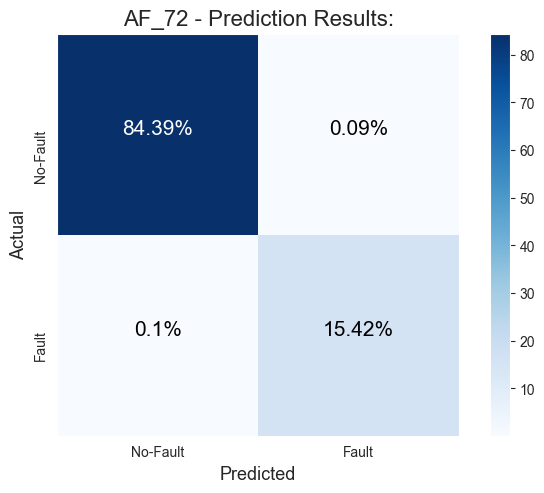

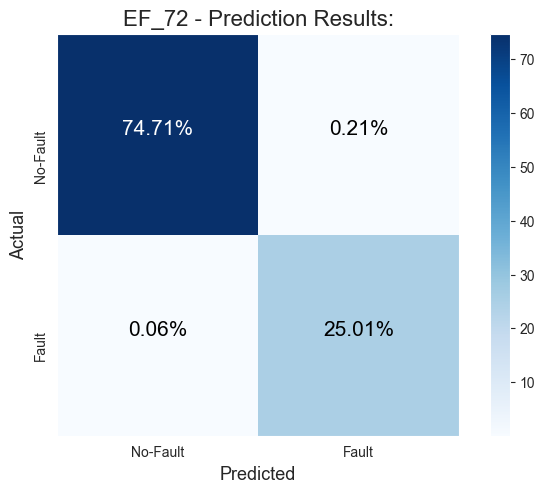

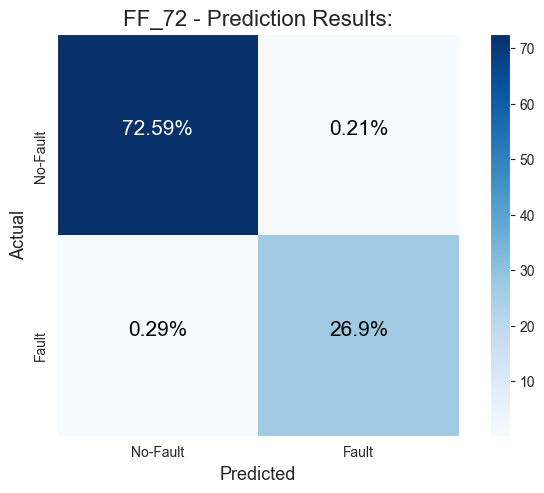

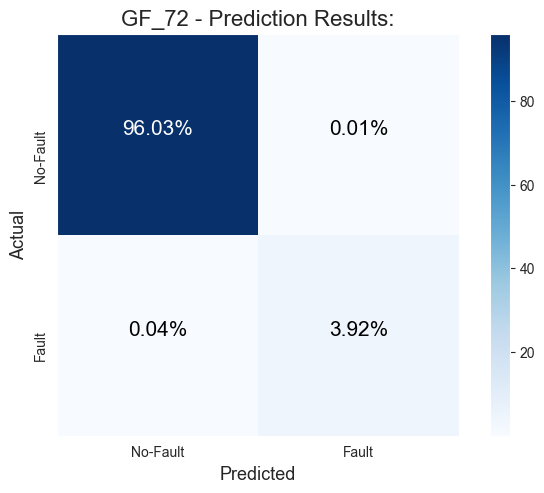

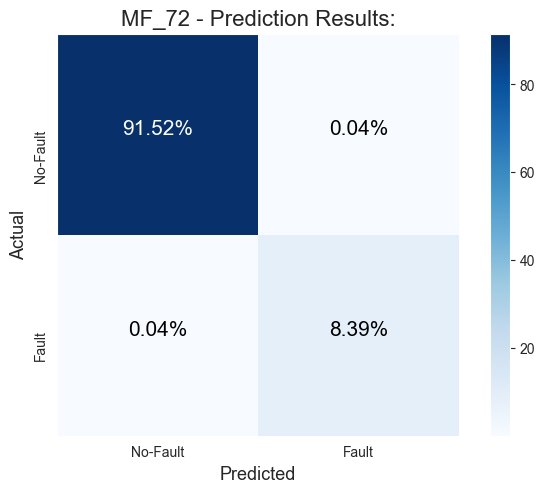

In [17]:
#Predicciones de clase
dataframe_class_predictions2 = deepcopy(dataframe_class_predictions)

#Outcomes de cada clase
dataframe_outcomes2 = deepcopy(dataframe_outcomes)

#Ajustamos los datos a la ventana temporal definida inicialmente
dataframe_class_predictions2  = dataframe_class_predictions2.iloc[MinI:MaxI-1]
dataframe_outcomes2  = dataframe_outcomes2.iloc[MinI:MaxI-1]

YVars = YVars72

for YVar in YVars:
    print ('') # Visual buffer
    y_true=dataframe_outcomes2[YVar]
    y_pred = dataframe_class_predictions2[YVar]
    Title = 'Confusion Matrix: '+YVar
    Title = YVar+' - Prediction Results:'

    cm = confusion_matrix(y_true, y_pred)

    # Normalizamos los porcentajes
    cm = cm.astype('float') / cm.sum()
    cm = (cm*100.0).round(2)
    PlotConfusionMatrix(cm,['No-Fault','Fault'],title=Title)

    plt.show()
    print('') # Buffer visual


Si comparamos la salida de la matriz de confusión para los 5 fallos, podemos observar que el modelo se comporta de una manera bastante similar para cada fallo en valores absolutos.

También podemos observar cómo, fruto del desbalance en los datos, el porcentaje mayor en número de clasificación para cada caso es corresponde a no fallos que, efectivamente, no correspondían a fallos (True Negative). Este desbalance también se manifiesta en que los fallos verdaderos (True Positive) que representan un porcentaje muy inferior. En el caso de AF, por ejemplo, del 100% de los datos clasificados, únicamente el 12,58% de las veces existía (y se detectó) de manera correcta un fallo.

A su vez, si nos fijamos en el porcentaje de muestras reconocidas incorrectamente, podemos observar que el 0,12 y el 2,94% de las veces hubo un resultado de falso negativo o falso positivo. En este caso, esto nos demuestra que en un aproximadamente un 3% del total de las ocasiones, existiendo un fallo, esto no fue detectado. Por el contrario, el modelo demostró ser muy bueno alertando de los fallos cuando, efectivamente, estos han ocurrido, ya que sólo en un 0,12% de las veces hay un error por detectar un falso positivo.

### Normalización por filas (Matriz de confusión común)

Esta matriz de confusión es útil para comprender cómo de bien se está clasificando cada clase. De esta forma, las celdas muestran el número de predicciones para cada categoría como un porcentaje de la cantidad real de esa clase, lo que indica qué porcentaje de la clase real fue correctamente clasificado o mal clasificado.

En este caso, esta matriz de confusión muestra el rendimiento del clasificador para cada clase por separado. En un escenario de clasificación desequilibrado, donde una de las clases es mucho más frecuente, la normalización por filas puede ser especialmente útil para evaluar la capacidad del modelo para identificar la clase menos frecuente.



8. A continuación vamos a representar la matriz de confusión normalizada por filas para ver realmente el rendimiento del clasificador en cada caso




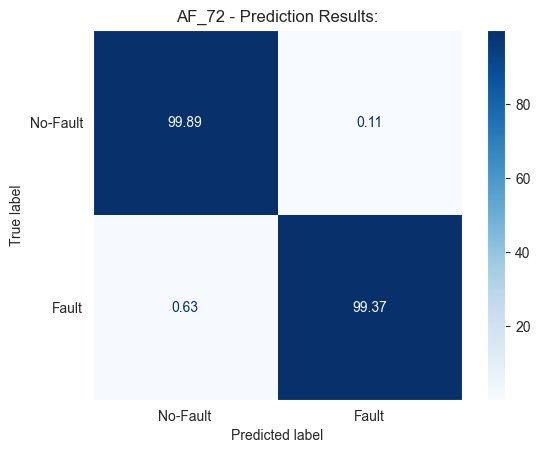

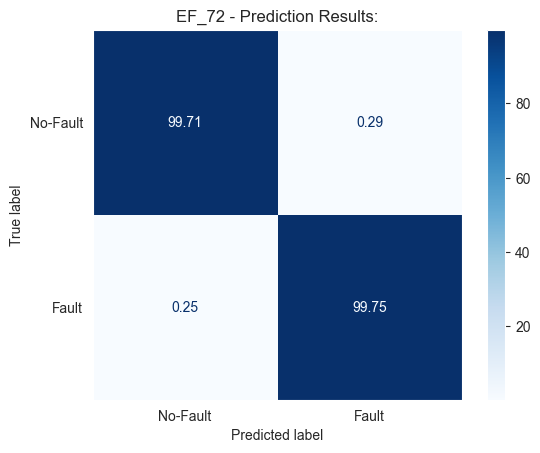

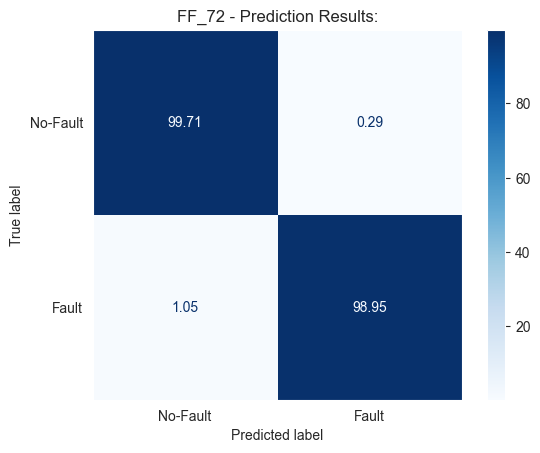

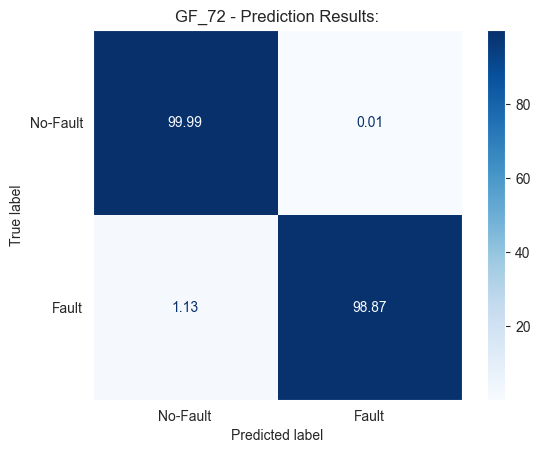

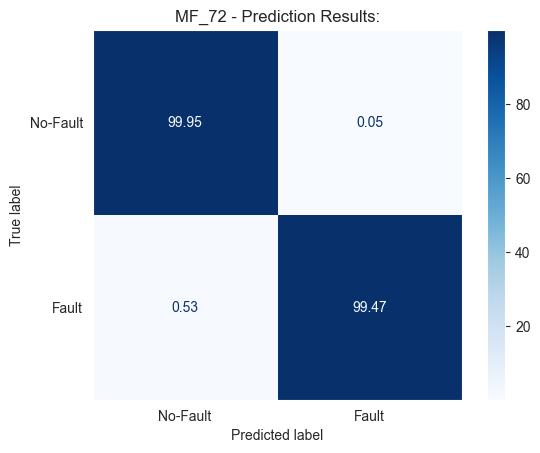

In [18]:
for YVar in YVars:
    print('\n')  # Buffer visual
    y_true = dataframe_outcomes2[YVar]
    y_pred = dataframe_class_predictions2[YVar]
    Title = YVar + ' - Prediction Results:'

    cm = confusion_matrix(y_true, y_pred)

    # Normalizamos los porcentajes
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = (cm_normalized * 100.0).round(2)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=['No-Fault', 'Fault'])

    disp.plot(values_format='.2f', cmap='Blues')
    plt.title(Title)
    plt.show()

    print('\n')  # Buffer visual


En estos resultados, la fila (que corresponde a cada clase) es la que suma 100, siendo cada valor el porcentaje que se da cada uno de los eventos (TP, FP, TN, FN)

En este caso podemos observar como el porcentaje de acierto tanto para los verdaderos negativos (TF) como en los verdaderos positivos es muy alto. A su vez, los casos en los que el modelo tuvo errores es muy bajo. Esto, aunque representado de una manera diferente, se corresponde con la información obtenida en la matriz de confusión previa.

De esta forma, nuevamente en el ejemplo de AF, podemos ver que el 99.86% de las veces que no había ningún fallo, el modelo lo predijo correctamente. Por lo tanto, el 0,16 de las veces que no lo había, el modelo se confundió y determinó que si existía.

De manera análoga, el 91.87% de las veces que el verdadero estado era de fallo, el modelo lo predijo correctamente. Sin embargo, en un 8,13% de estas veces, no fue capaz de predecirlo y, por lo tanto, no alertó sobre ello.

Estos resultados se corresponden como la distribución de clases, donde la mayoritaria (comportamiento normal) obtiene mejores resultados medios en comparación a la minoritaria (presencia de fallos) por lo que los algoritmos, al tener más ejemplos tienen a capturar mejor los patrones de los datos y por lo tanto a hacer mejores predicciones.







### Toma de decisiones de clasificación

Para convertir la salida de un clasificador probabilístico en etiquetas de clase se necesita un umbral de clasificación. Este umbral determina la probabilidad mínima requerida para realizar una predicción positiva. Diferentes umbrales pueden llevar a diferentes compensaciones entre precisión y exhaustividad (recall). El umbral de 0.5 es a menudo una elección predeterminada, pero puede no ser óptimo en problemas del mundo real. Esto depende de la tarea específica y del costo de los errores de falsos positivos y falsos negativos. Por ello, en función de cuál sea la aplicación de nuestro modelo, puede ser más o menos crítico priorizar un tipo de fallo respecto a otro.

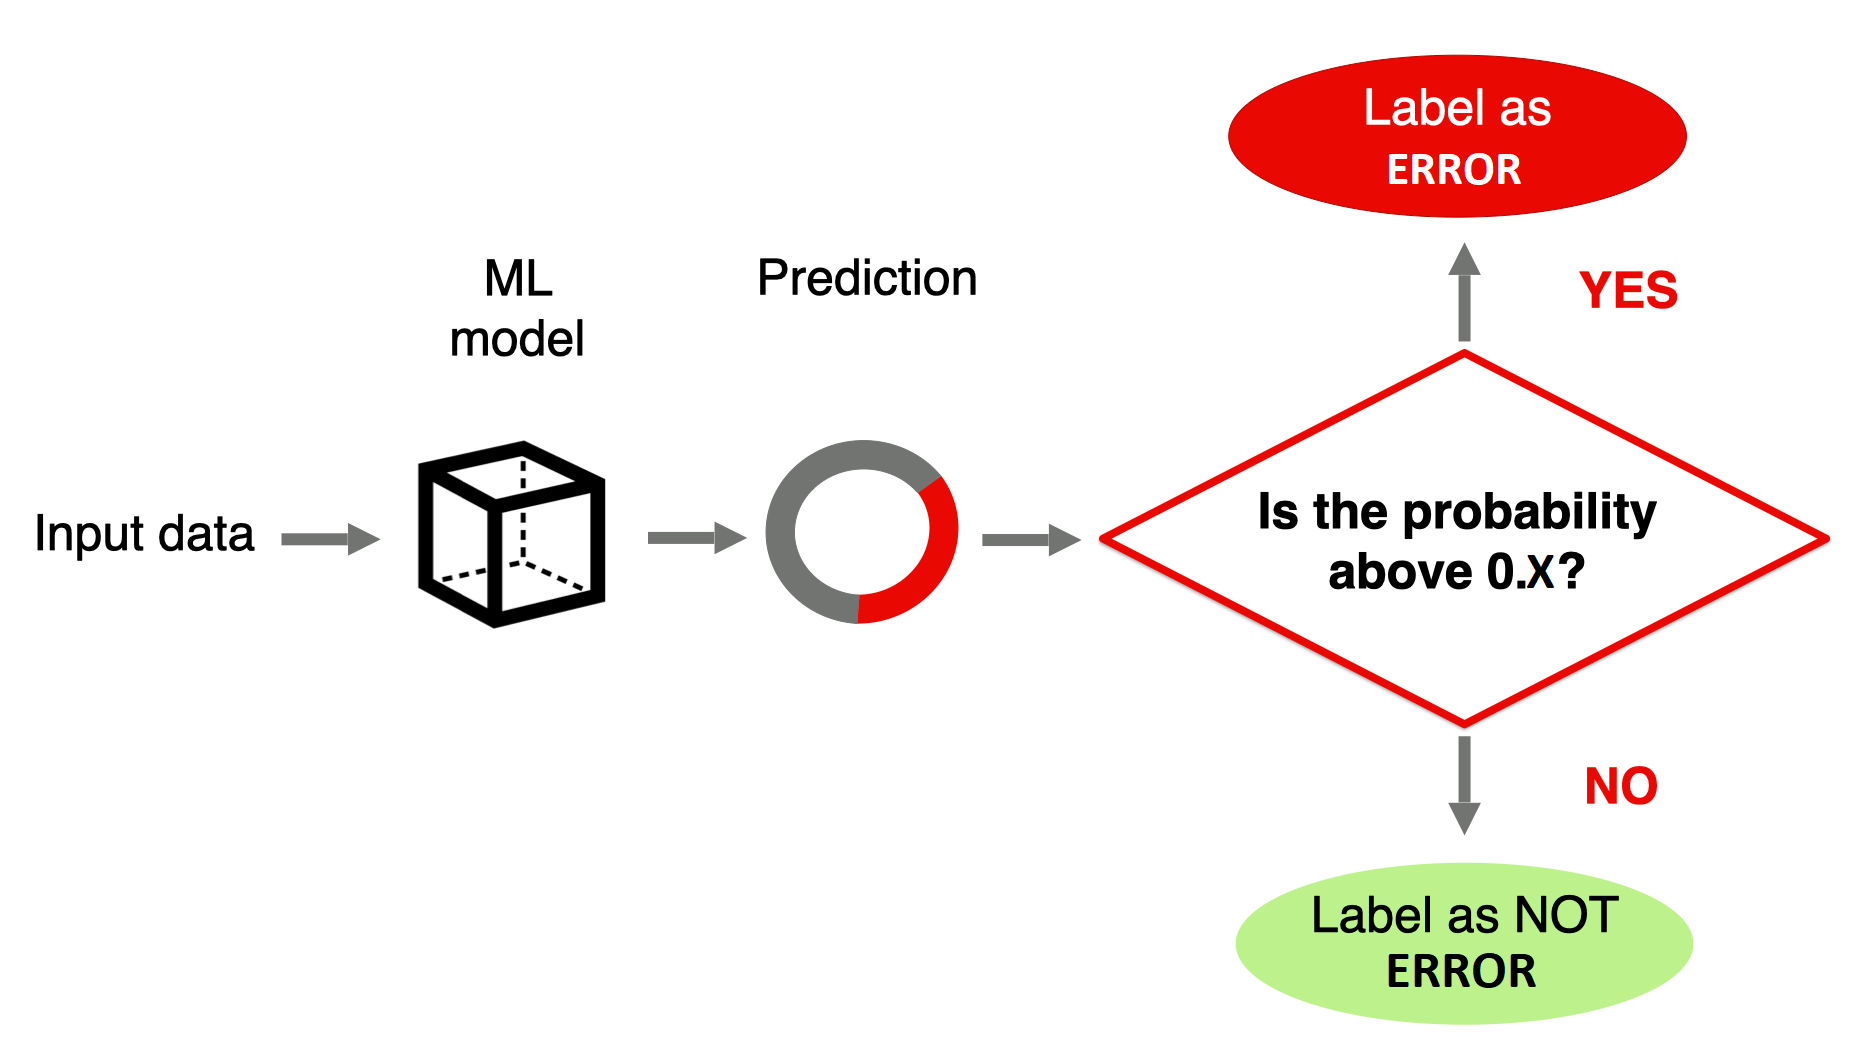





En el caso que estamos estudiando del aerogenerador, puede darse el caso de que se considere prioritario identificar todos los fallos, incluso a expensas de falsos positivos. Es decir, a expensas de veces en las que se cree que hay algún error, pero sin embargo el funcionamiento es correcto. En este caso, se priorizaría evitar fallos aunque eso implicase un mayor gasto de mantenimiento derivado por hacer revisiones en ocasiones en las que no es necesario.

En otras ocasiones puede ocurrir que el coste de mantenimiento sea el factor prioritario y que por el contrario se consideren aceptables algunas averías fruto de no haber podido identificarlas. Esto podría ocurrir si, por ejemplo, se están monitorizando activos como aerogeneradores en zonas muy remotas donde movilizar al personal para hacer una revisión innecesaria es resulta muy costoso a nivel de recursos.

Esta decisión suele depender de un análisis de riesgo/beneficio y una evaluación de los costes tanto a nivel personal como económico (no es lo mismo la avería en un aerogenerador que en un avión). Una forma habitual de ajustar el comportamiento de un modelo es priorizar una métrica, ya sea el recall o la precisión. De esta forma, podemos priorizar un determinado comportamiento.


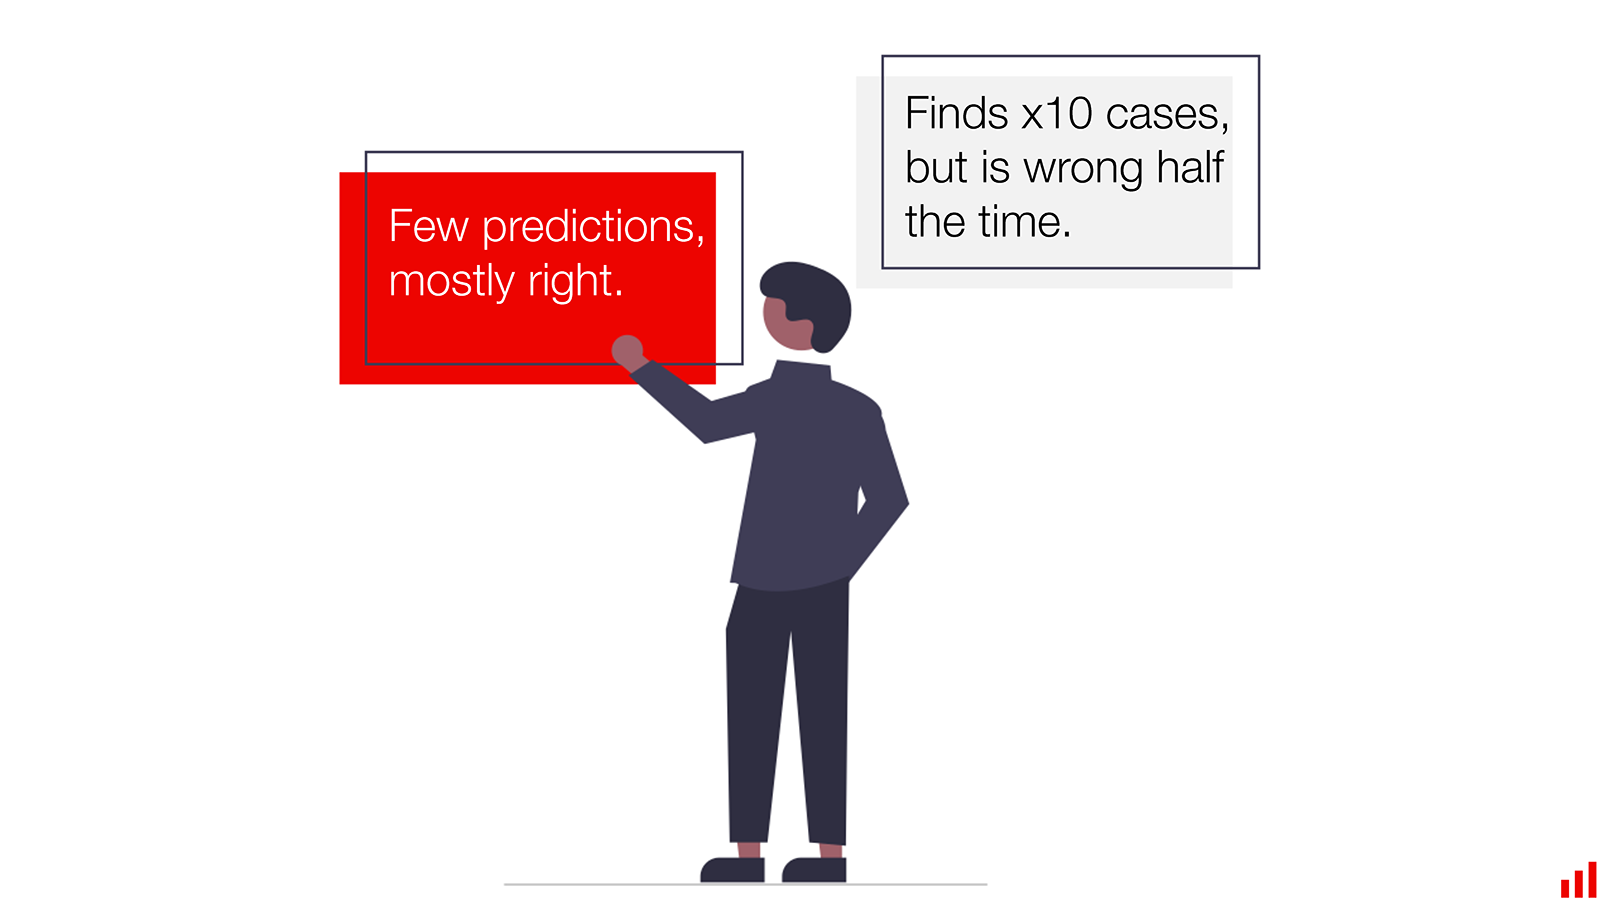

----




## Optimización del umbral de classificación

Por ello, el umbral de clasificación es un parámetro importante a la hora de construir y evaluar modelos de clasificación. Puede influir significativamente en el rendimiento del modelo y en las decisiones tomadas a partir de sus predicciones. En función del problema específico y del equilibrio deseado entre precisión y recuperación, es posible que desee elegir un umbral diferente.

Vamos a repasar lo que era la precisión y el recall

* La **precisión** mide la relación entre los verdaderos positivos (TP) y todos los positivos predichos (TP + falsos positivos (FP)). Refleja la frecuencia con la que el modelo acierta cuando predice la clase positiva.

* El **recall** mide la relación entre los verdaderos positivos (TP) y todos los positivos reales (TP + falsos negativos (FN)). Refleja la proporción de casos positivos que el modelo puede detectar en el conjunto de datos.

Cada métrica tiene sus limitaciones. La precisión da prioridad a la exactitud, pero puede ignorar el costo de los casos positivos omitidos. Es decir, el modelo es muy fiable cuando identifica un fallo, pero puede pasar por alto otros de manera errónea. Por otro lado, el recall pone énfasis en la "integridad", identificando más posibles positivos a expensas de marcar erróneamente instancias que no son fallos. Ambos tipos de errores pueden resultar costosos, dependiendo del caso de uso específico. Existen dos circunstancias que pueden guiar esta elección:

* Priorizar la **Precisión** (disminuir los Falsos Positivos): Al aumentar el umbral, el modelo requerirá una mayor "confianza" antes de predecir una instancia como positiva, lo que debería aumentar la precisión (menos falsos positivos), pero también puede reducir el recall (más falsos negativos). Esto es útil cuando las consecuencias de un falso positivo son graves. Por ejemplo, podríamos preferir detener el funcionamiento de un activo ante posibles fallos, aunque sea sin necesidad, si las consecuencias de un fallo son severas.

* Priorizar el **Recall** (disminuir los Falsos Negativos): Al reducir el umbral, el modelo predecirá más fácilmente una instancia como positiva, lo que debería aumentar el recall (menos falsos negativos) a expensas de disminuir la precisión (más falsos positivos). Esto es adecuado en situaciones donde los falsos negativos tienen consecuencias graves. Por ejemplo, si el costo de detener un activo por mantenimiento es menor que el impacto de un fallo, es preferible minimizar los falsos negativos.

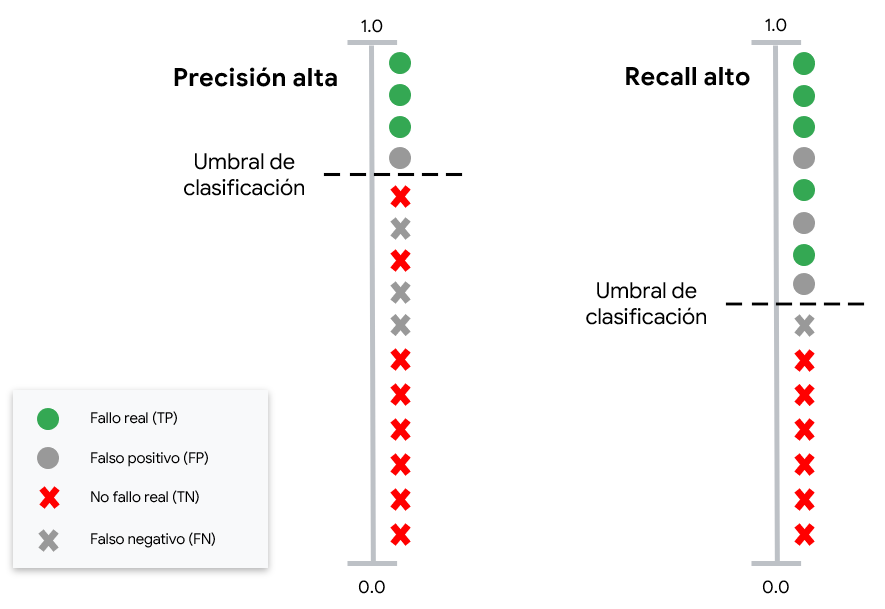


Para obtener un modelo más equilibrado, o uno en el que tengamos una distribución más conveniente de verdaderos positivos y verdaderos negativos, podemos ajustar este umbral a un valor diferente, asegurándonos así de que estamos interpretando las probabilidades de acuerdo a nuestra estrategia de toma de decisiones.

En cualquier caso, es importante tener en cuenta que modificar demasiado el umbral provocará un ajuste excesivo.

Para realizar esta optimización, en primer lugar, vamos a ver el efecto de modificar el valor del umbral de clasificador.


9. Definimos manualmente un valor de umbral entre el 0 y el 1. A menor valor menor será la probabilidad necesaria para considerar una predicción como positiva y a la inversa, a mayor valor, más exigente será el modelo antes de dar esa salida en forma de predicción.

In [53]:
default_threshold = 0.5
threshold = 0.0001

In [54]:
# Supongamos que YVars contiene los nombres de las columnas para cada tipo de fallo
metrics_summary = defaultdict(dict)  # Diccionario para almacenar los resúmenes de las métricas por tipo de fallo

# Iterar a través de cada tipo de fallo en YVars
for YVar in YVars:
    # Diccionario para almacenar las métricas de evaluación para cada umbral del tipo de fallo actual
    metrics_dict = defaultdict(list)

    # Calcular y almacenar métricas con el umbral por defecto
    y_pred_default = (dataframe_prob_predictions2[YVar] >= default_threshold).astype(int)
    precision_default, recall_default, fscore_default, _ = precision_recall_fscore_support(
        dataframe_outcomes2[YVar], y_pred_default, average='binary')


    # Generar predicciones binarias basadas en el umbral actual
    y_pred = (dataframe_prob_predictions2[YVar] >= threshold).astype(int)

    # Calcular métricas de rendimiento
    precision, recall, fscore, _ = precision_recall_fscore_support(dataframe_outcomes2[YVar], y_pred, average='binary')

    # Almacenar las métricas
    metrics_dict['threshold'].append(threshold)
    metrics_dict['precision'].append(precision)
    metrics_dict['recall'].append(recall)
    metrics_dict['fscore'].append(fscore)

    # Convertir el diccionario de métricas en un DataFrame para análisis
    metrics_df = pd.DataFrame(metrics_dict)

    # Almacenar el resumen de las métricas en el diccionario general
    metrics_summary[YVar] = {
        'default_precision': precision_default,
        'default_recall': recall_default,
        'default_fscore': fscore_default,
        'optimal_threshold': threshold,
        'optimal_precision': precision,
        'optimal_recall': recall,
        'optimal_fscore': fscore
    }

    # Imprimir la comparativa para el tipo de fallo actual
    print(f"Para el tipo de fallo '{YVar}':")
    print(f" - Con umbral por defecto ({default_threshold}%): Precisión = {precision_default:.4f}, Recall = {recall_default:.4f}, F1-Score = {fscore_default:.4f}")
    print(f" - Con umbral adaptado ({threshold}%): Precisión = {precision:.4f}, Recall = {recall:.4f}, F1-Score = {fscore:.4f}\n")

# Convertir el resumen de métricas en DataFrame para un análisis más fácil
metrics_summary_df = pd.DataFrame(metrics_summary).T
print(metrics_summary_df)




Para el tipo de fallo 'AF_72':
 - Con umbral por defecto (0.5%): Precisión = 0.9942, Recall = 0.9937, F1-Score = 0.9939
 - Con umbral adaptado (0.0001%): Precisión = 0.4710, Recall = 1.0000, F1-Score = 0.6404

Para el tipo de fallo 'EF_72':
 - Con umbral por defecto (0.5%): Precisión = 0.9915, Recall = 0.9975, F1-Score = 0.9945
 - Con umbral adaptado (0.0001%): Precisión = 0.6246, Recall = 1.0000, F1-Score = 0.7690

Para el tipo de fallo 'FF_72':
 - Con umbral por defecto (0.5%): Precisión = 0.9921, Recall = 0.9895, F1-Score = 0.9908
 - Con umbral adaptado (0.0001%): Precisión = 0.6488, Recall = 1.0000, F1-Score = 0.7870

Para el tipo de fallo 'GF_72':
 - Con umbral por defecto (0.5%): Precisión = 0.9977, Recall = 0.9887, F1-Score = 0.9932
 - Con umbral adaptado (0.0001%): Precisión = 0.1684, Recall = 1.0000, F1-Score = 0.2882

Para el tipo de fallo 'MF_72':
 - Con umbral por defecto (0.5%): Precisión = 0.9947, Recall = 0.9947, F1-Score = 0.9947
 - Con umbral adaptado (0.0001%): Precis


Se puede observar como cuando subimos el umbral, aumenta la precisión. Por el contrario, al bajarlo, aumenta el recall. De esta manera, umbrales más bajos favorecen la detección de la clase positiva asumiendo errores de falsos positivos y umbrales más altos aseguran más la certeza de las predicciones positivas a costa de falsos negativos.



El balance entre precisión y recall puede representarse dráficamente a través de la **curva precisión recall**, que muestra los valores de ambas métricas obtenidas de un modelo de clasificación a varios umbrales. Por lo tanto, permite entender cómo los cambios en el umbral de clasificación afectan la capacidad del modelo.




10. Representamos la curva de Precision-Recall

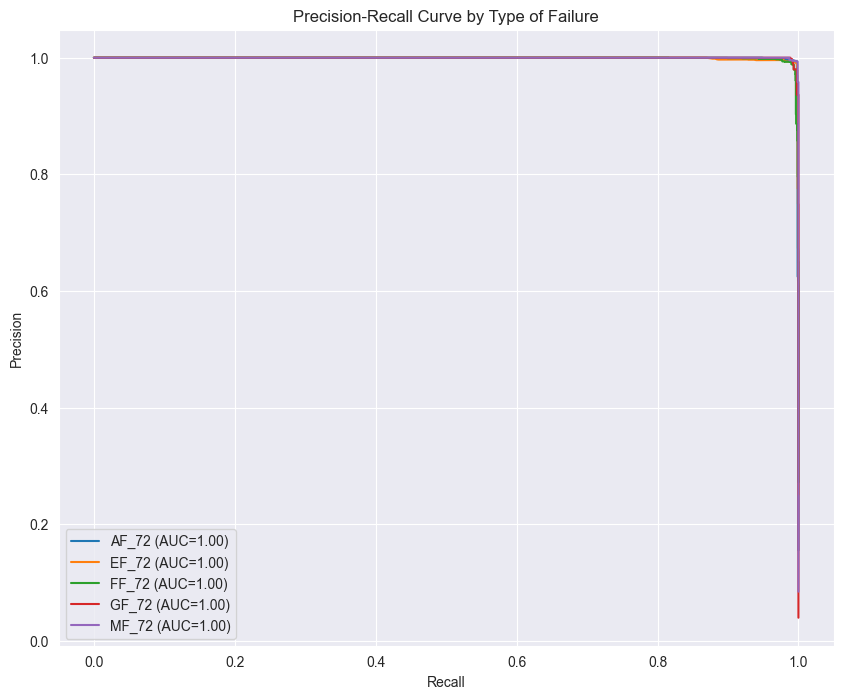

In [55]:
# Crear figuras para los gráficos
plt.figure(figsize=(10, 8))

# Iterar a través de cada tipo de fallo
for YVar in YVars:
    y_true = dataframe_outcomes2[YVar]
    y_scores = dataframe_prob_predictions2[YVar]

    # Calcula la precisión y el recall para varios umbrales de decisión
    precision, recall, thresholds = precision_recall_curve(y_true, y_scores)

    # Calcula el área bajo la curva (AUC) de la curva precisión-recall
    auc_score = auc(recall, precision)

    # Trazar la curva de precisión-recall
    plt.plot(recall, precision, label=f'{YVar} (AUC={auc_score:.2f})')

# Personaliza el gráfico
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve by Type of Failure')
plt.legend(loc='best')
plt.grid(True)
plt.show()


Se puede observar que el gráfico tiene una tendencia descendente. Es decir, a medida de aumenta el recall, disminuye la precisión y viceversa. Los mejores resultados se corresponden con aquellos que están más cerca del vertice superior derecha. Ahí es donde se optimizan tanto los valores de precisión como de equilibrio. Por ello, a mayor area por debajo de la curva, mejor rendimiento general del modelo.



Ahora vamos a centrarnos en buscar el valor de umbral que maximiza nuestro objetivo.

Cuando lo que se busca es equilibrar el rendimiento del clasificador, normalmente suele buscar maximizar la métrica de F1.

* La **F1** es la media armónica de la precisión y el recall, y se utiliza para evaluar la precisión general de un modelo de clasificación binaria.

En nuestro caso, vamos a centrarnos en asegurarnos que somos capaces de detectar el mayor número de fallos posible. Esto implicaría aumentar el recall y evitar en la medida de lo posible los falsos negativas (FN). Por ello, podríamos fijar un umbral de decisión más bajo de manera que se priorice, incluso con probabilidades más bajas, que cualquier atisbo de fallo sea detectado.

Es posible que esto haga que el modelo tenga una precisión baja. De hecho, si sustituimos en el ejemplo anterior el umbral por 0, vemos que alcanzamos recalls perfectos. Sin embargo, esto no mejora nuestro modelo ya que la precisión se derrumba. Por ello, vamos a considerar para esta decisión la media de la F1 y el Recall, de manera que nos aseguremos de que el rendimiento del modelo siga siendo bueno y mejore el recall a expensas de perder algo de precisión.



11. Vamos a calcular el umbral que maximiza la media entre el F1 y el Recall. Es decir, aquel que consigue los mejores resultados ponderando ambas métricas. El siguiete código itera por todos los valores de umbral entre 0 y 1 en pasos de 0.1 y selecciona para cada modelo aquel en el que se obtienen los mejores resultados

In [29]:
# Supongamos que YVars contiene los nombres de las columnas para cada tipo de fallo
metrics_summary = defaultdict(dict)  # Diccionario para almacenar los resúmenes de las métricas por tipo de fallo

# Crear un rango de umbrales desde 0 a 1 con un paso de 0.01
thresholds = np.linspace(0, 1, 101)

# Umbral por defecto para la mayoría de los clasificadores
default_threshold = 0.5

# Iterar a través de cada tipo de fallo en YVars
for YVar in YVars:
    # Diccionario para almacenar las métricas de evaluación para cada umbral del tipo de fallo actual
    metrics_dict = defaultdict(list)

    # Calcular y almacenar métricas con el umbral por defecto
    y_pred_default = (dataframe_prob_predictions2[YVar] >= default_threshold).astype(int)
    precision_default, recall_default, fscore_default, _ = precision_recall_fscore_support(
        dataframe_outcomes2[YVar], y_pred_default, average='binary')

    # Iterar a través de cada umbral y evaluar el modelo para el tipo de fallo actual
    for threshold in thresholds:
        # Generar predicciones binarias basadas en el umbral actual
        y_pred = (dataframe_prob_predictions2[YVar] >= threshold).astype(int)

        # Calcular métricas de rendimiento
        precision, recall, fscore, _ = precision_recall_fscore_support(dataframe_outcomes2[YVar], y_pred, average='binary')

        # Almacenar las métricas
        metrics_dict['threshold'].append(threshold)
        metrics_dict['precision'].append(precision)
        metrics_dict['recall'].append(recall)
        metrics_dict['fscore'].append(fscore)

    # Convertir el diccionario de métricas en un DataFrame para análisis
    metrics_df = pd.DataFrame(metrics_dict)

    # Encontrar el umbral óptimo basado en el F1-Score
    metrics_df['mean'] = ((metrics_df['recall'] + metrics_df['fscore']) /2)
    optimal_idx = metrics_df['mean'].idxmax()
    optimal_threshold = metrics_df.loc[optimal_idx, 'threshold']
    optimal_precision = metrics_df.loc[optimal_idx, 'precision']
    optimal_recall = metrics_df.loc[optimal_idx, 'recall']
    optimal_fscore = metrics_df.loc[optimal_idx, 'fscore']

    # Almacenar el resumen de las métricas en el diccionario general
    metrics_summary[YVar] = {
        'default_precision': precision_default,
        'default_recall': recall_default,
        'default_fscore': fscore_default,
        'optimal_threshold': optimal_threshold,
        'optimal_precision': optimal_precision,
        'optimal_recall': optimal_recall,
        'optimal_fscore': optimal_fscore
    }

    # Imprimir la comparativa para el tipo de fallo actual
    print(f"Para el tipo de fallo '{YVar}':")
    print(f" - Con umbral por defecto: Precisión = {precision_default:.4f}, Recall = {recall_default:.4f}, F1-Score = {fscore_default:.4f}")
    print(f" - Con umbral adaptado: Umbral óptimo = {optimal_threshold}, Precisión = {optimal_precision:.4f}, Recall = {optimal_recall:.4f}, F1-Score = {optimal_fscore:.4f}\n")

# Convertir el resumen de métricas en DataFrame para un análisis más fácil
metrics_summary_df = pd.DataFrame(metrics_summary).T
print(metrics_summary_df)



Para el tipo de fallo 'AF_72':
 - Con umbral por defecto: Precisión = 0.9942, Recall = 0.9937, F1-Score = 0.9939
 - Con umbral adaptado: Umbral óptimo = 0.21, Precisión = 0.9943, Recall = 0.9977, F1-Score = 0.9960

Para el tipo de fallo 'EF_72':
 - Con umbral por defecto: Precisión = 0.9915, Recall = 0.9975, F1-Score = 0.9945
 - Con umbral adaptado: Umbral óptimo = 0.45, Precisión = 0.9915, Recall = 0.9979, F1-Score = 0.9947

Para el tipo de fallo 'FF_72':
 - Con umbral por defecto: Precisión = 0.9921, Recall = 0.9895, F1-Score = 0.9908
 - Con umbral adaptado: Umbral óptimo = 0.39, Precisión = 0.9882, Recall = 0.9934, F1-Score = 0.9908

Para el tipo de fallo 'GF_72':
 - Con umbral por defecto: Precisión = 0.9977, Recall = 0.9887, F1-Score = 0.9932
 - Con umbral adaptado: Umbral óptimo = 0.05, Precisión = 0.9800, Recall = 0.9977, F1-Score = 0.9888

Para el tipo de fallo 'MF_72':
 - Con umbral por defecto: Precisión = 0.9947, Recall = 0.9947, F1-Score = 0.9947
 - Con umbral adaptado: Umb

De acuerdo con los resultados, podemos ver como umbrales en torno al 0,2-0,3 consiguen, en todos los modelos mejorar los valores de recall. Como contrapartieda, esta ganancia se traslada en una reducción en la precisión, aunque el Fscore se mantiene de manera bastante similar el clasificador con el umbral por defecto.

De esta forma, habríamos encontrado un valor de umbral que nos permite tener un modelo más capaz de tomar las decisiones en base a nuestro criterio de prioridad.


-----

# 2. Ajuste del modelo para detección multiclase

Ahora, en esta segunda parte, vamos a dejar a un lado el trabajo realizado para la creación de ventanas y selección de características.

Por ello, vamos a volver a los datos originales y combinar los datos del scada con los de los fallos.

Con ellos, vamos a entrenar un modelo multiclase que sea capaz no solo de determinar la existencia o no de un tipo de fallo (clasificación binaria) si no el fallo específico en sí.

12. Comenzamos por tanto importando esos archivos originales del dataset y combinándolos

In [75]:
scada_dataset = './data/scada_data.csv'
scada_df = pd.read_csv(scada_dataset)
scada_df['DateTime'] = pd.to_datetime(scada_df['DateTime'])

In [76]:
fault_dataset = './data/fault_data.csv'
fault_df = pd.read_csv(fault_dataset)
fault_df['DateTime'] = pd.to_datetime(scada_df['DateTime'])

In [77]:
# Combine scada and fault data
df_combine = scada_df.merge(fault_df, on='Time', how='outer')


13. Después nos aseguramos de limpiar el conjunto de datos de manera que, donde no haya valores (recordad que los datos se recolectaron en fechas diferentes), en vez de un NaN se aplique un valor de "NF" o No Fallo (Non Failure). Como vimos que se trataba de un dataset muy desbalanceado, vamos nuevamente a contar sus valores

In [78]:
# Replace records that has no fault label (NaN) as 'NF' (no fault)
df_combine['Fault'] = df_combine['Fault'].replace(np.nan, 'NF')

df_combine

,DateTime_x,Time,Error,WEC: ava. windspeed,WEC: max. windspeed,WEC: min. windspeed,WEC: ava. Rotation,WEC: max. Rotation,WEC: min. Rotation,WEC: ava. Power,...,Fan inverter cabinet temp.,Ambient temp.,Tower temp.,Control cabinet temp.,Transformer temp.,RTU: ava. Setpoint 1,Inverter averages,Inverter std dev,DateTime_y,Fault
0,2014-05-01 00:00:00,1398920448,0,6.9,9.4,2.9,0.00,0.02,0.00,0,...,25,12,14,24,34,2501,25.272728,1.103713,NaT,NF
1,2014-05-01 00:09:00,1398920960,0,5.3,8.9,1.6,0.00,0.01,0.00,0,...,25,12,14,24,34,2501,25.272728,1.103713,NaT,NF
2,2014-05-01 00:20:00,1398921600,0,5.0,9.5,1.4,0.00,0.04,0.00,0,...,25,12,14,24,34,2501,25.272728,1.103713,NaT,NF
3,2014-05-01 00:30:00,1398922240,0,4.4,8.3,1.3,0.00,0.08,0.00,0,...,25,12,14,24,34,2501,25.272728,1.103713,NaT,NF
4,2014-05-01 00:39:00,1398922752,0,5.7,9.7,1.2,0.00,0.05,0.00,0,...,25,12,14,23,34,2501,25.272728,1.103713,NaT,NF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49129,2015-04-08 23:20:00,1428553216,0,3.9,5.5,2.2,6.75,7.40,6.01,147,...,28,9,17,27,35,3050,24.454546,3.474583,NaT,NF
49130,2015-04-08 23:30:00,1428553856,0,3.9,5.6,2.9,6.64,7.06,6.33,128,...,28,9,17,27,35,3050,24.454546,3.445683,NaT,NF
49131,2015-04-08 23:39:00,1428554368,0,4.2,6.7,2.6,7.18,8.83,6.22,163,...,28,9,18,27,34,3050,24.363636,3.413876,NaT,NF
49132,2015-04-08 23:50:00,1428555008,0,4.1,6.6,2.7,7.02,7.94,6.20,160,...,28,9,17,27,34,3050,24.000000,3.376389,NaT,NF


<Axes: title={'center': 'Fault Modes'}, ylabel='count'>

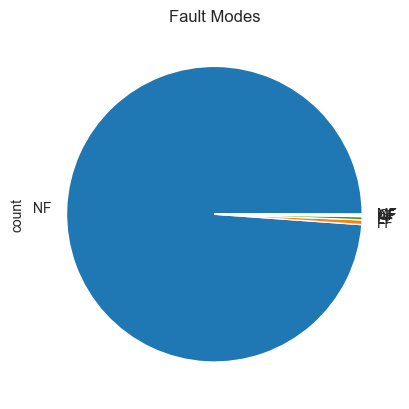

In [79]:
df_combine.Fault.value_counts()
df_combine
df_combine.Fault.value_counts().plot.pie(title='Fault Modes')

El número de instancias de tipo NF en el dataset original es excesivamente superior a las de los fallos.


14. Por ello, vamos a reducir el número de instancias de No fallo a 300 para hacer una "undersampling" y balancear las clases de datos. Una vez reducidas, seleccionamos aquellas instancias que se correspondan a fallos y concatenamos ambos nuevos dataframes

<Axes: title={'center': 'Fault Modes'}, ylabel='count'>

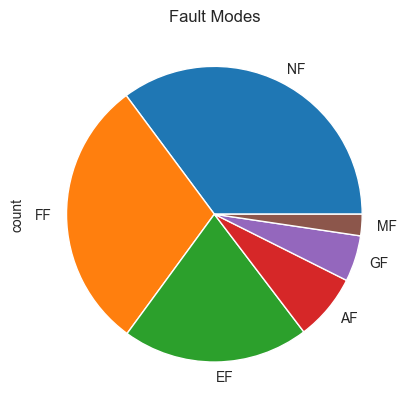

In [80]:
df_nf = df_combine[df_combine.Fault=='NF'].sample(300, random_state=42)
df_f = df_combine[df_combine.Fault!='NF']
df_combine = pd.concat((df_nf, df_f), axis=0).reset_index(drop=True)
df_combine.Fault.value_counts().plot.pie(title='Fault Modes')

Aunque en este ejercicio no vamos a realizar selección de características, si que debemos eliminar aquellas que resultan irrelevantes para la clasificación.

15. Por ello, eliminamos las columnas de fecha, hora y error ya que únicamente estamos evaluando instancias correspondientes a instantes específicos.

In [81]:
train_df = df_combine.drop(columns=['DateTime_x', 'Time', 'Error', 'DateTime_y'])

A continuación, vamos a construir un modelo predictivo para clasificar los modos de fallo del aerogenerador basándonos en la información o estado de los componentes del aerogenerador. A diferencia de hasta ahora, en esta ocasión se trata de una tarea de clasificación multiclase.

Dado que nuestros datos de entrenamiento, incluso después del proceso de undersampling sigue muy desequilibrado para cada modo de fallo. Vamos a ver otra forma de balancear nuestras clases. En este caso, utilizaremos una técnica de oversampling llamada SMOTE (Synthetic Minority Oversampling Technique) para sobre muestrear las clases minoritarias. Esta técnica crea ejemplos sintéticos de la clase minoritaria en lugar de simplemente duplicar los existentes (como haría el sobre muestreo simple). Funciona seleccionando ejemplos que están cerca en el espacio de características (utilizando un algoritmo de KNN), dibujando una línea entre los ejemplos en el espacio de características y luego generando nuevos ejemplos a lo largo de esa línea.

Como algoritmo de clasificación utilizamos es LightGBM (Gradient Boosting Machine), un algoritmo se basa en el mismo principio de  gradient boosting aplicándolo mediante un método más eficiente y optimizado.

A su vez, para evitar el sobreajuste, realizamos una validación cruzada (cross validation) estratificada K-Fold con 5 fold (tal y como vimos en los ejercicios del laboratorio pasado)

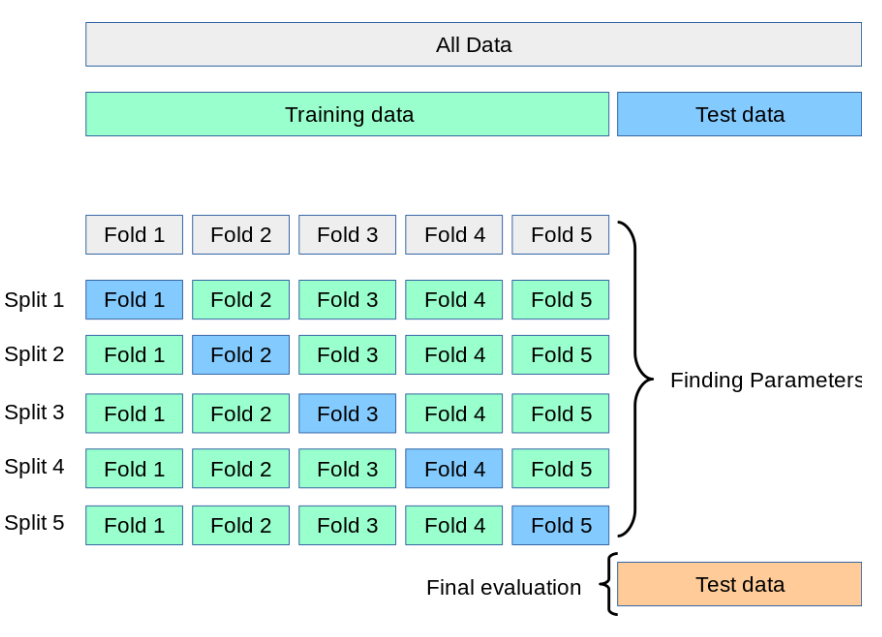

(https://scikit-learn.org/stable/modules/cross_validation.html)

En este proceso de crossvalidation, el conjunto de entrenamiento se dividirá en conjunto de entrenamiento y conjunto de validación en un número determinado de iteraciones (definidas por el número de folds). Por lo tanto, para asegurarse de que el conjunto de entrenamiento está equilibrado, el SMOTE debe hacerse únicamente con los datos de entrenamiento, ya que si no el resultado se vería afectado por data leackage.


Para ello, vamos a emplear el método de **pipeline**: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html



16. Extraemos los datos en datos de entrada (características) y de salida (output/clases) y dividimos los datos en entranamiento y est. Posteriormente creamos el pipeline coon los pasos que queremos realizar durante el proceso de entrenamiento en el cross-validation. Imprimimos los resultados del proceso de validación cruzada que se corresponden con la midia de los resultados de cada iteración.

In [69]:
X = train_df.iloc[:,:-1]
y = train_df.iloc[:,-1]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)

# Make pipeline of SMOTE, scaling, and classifier
pipe = make_pipeline(SMOTE(), StandardScaler(), LGBMClassifier(random_state=0))

# Define multiple scoring metrics
scoring = {
    'acc': 'accuracy',
    'prec_macro': 'precision_macro',
    'rec_macro': 'recall_macro',
    'f1_macro': 'f1_macro'
}

# Stratified K-Fold
stratkfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Return a dictionary of all scorings
cv_scores = cross_validate(pipe, X_train, y_train, cv=stratkfold, scoring=scoring)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001249 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6332
[LightGBM] [Info] Number of data points in the train set: 870, number of used features: 60
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Wa

In [70]:
# Print scoring results from dictionary
for metric_name, metric_value in cv_scores.items():
    mean = np.mean(metric_value)
    print(f'{metric_name}: {np.round(metric_value, 4)}, Mean: {np.round(mean, 4)}')

fit_time: [0.7855 0.6318 0.6236 0.6387 0.6399], Mean: 0.6639
score_time: [0.0194 0.0194 0.0183 0.0152 0.016 ], Mean: 0.0177
test_acc: [0.7282 0.7647 0.7647 0.6471 0.7255], Mean: 0.726
test_prec_macro: [0.6153 0.6543 0.6272 0.556  0.6311], Mean: 0.6168
test_rec_macro: [0.6246 0.606  0.6455 0.5404 0.6004], Mean: 0.6034
test_f1_macro: [0.619  0.6166 0.6308 0.5449 0.6136], Mean: 0.605


Como era de esperar, obtenemos unos inferiores a los del laboratorio anterior. Esto se debe, en primer lugar, a que ya no estabamos tratando con modelos binarios donde se clasifica con 1 o con 0, si no que ahora tenemos un único modelo para 6 clases.

Por otro lado, el crear ventanas de 24/72/48h nos ayuda a reeducir la granularidad y a suavizar la variabilidad a corto plazo, lo que es útil para identificar tendencias más significativas. A su vez, esta agregación por ventanas aumenta la cantidad de datos de cada clase.

17. Comprobamos los resultados finales con el test set que habíamos reservado previamente. Esto es equivalente a usar train, test y validación

In [71]:
# Fit pipeline to train set
pipe.fit(X_train, y_train)

# Predict on test set
y_pred = pipe.predict(X_test)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000692 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6523
[LightGBM] [Info] Number of data points in the train set: 1086, number of used features: 60
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [W

In [72]:
# Classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          AF       0.68      0.48      0.57        27
          EF       0.47      0.58      0.52        67
          FF       0.68      0.60      0.64       109
          GF       0.93      1.00      0.96        13
          MF       0.27      0.57      0.36         7
          NF       0.92      0.90      0.91       119

    accuracy                           0.70       342
   macro avg       0.66      0.69      0.66       342
weighted avg       0.73      0.70      0.71       342



Sin embargo, todavía podemos intentar mejorar el modelo.

Esto implica ajustar los parámetros para optimar los resultados para la métrica deseada. Para ello podemos emplear un enfoque de búsqueda en cuadrícula (Grid Search) para probar sistemáticamente combinaciones de parámetros y encontrar la configuración óptima de los hiperparametros del algoritmo LightGBM.

De esta forma, automáticamente se prueban todas las combinaciones posibles de hiperparámetros el conjunto de datos de entrenamiento y se evalúan mediante el proceso de cross-validation, priorizando aquella métrica que se considere de interés.

18. Realizamos el ajuste de parámetros y entrenamos un nuevo modelo con la combinación resultante, buscando optimizar nuevamente la métrica recall

In [73]:
# Define parameter search grid
param_grid = {
    'lgbmclassifier__n_estimators': [6, 16, 24, 96],
    'lgbmclassifier__num_leaves': [4, 8, 12],
    'lgbmclassifier__reg_alpha': [0, 0.5, 1, 1.5, 2],  # Ampliado para explorar desde ninguna regularización hasta regularización más fuerte
    'lgbmclassifier__reg_lambda': [0, 0.5, 1, 1.5, 2],  # Similar para el parámetro de regularización L2
    'lgbmclassifier__boosting_type': ['gbdt', 'dart']  # Incluye dos tipos de boosting para mayor variedad
}

# Grid search CV
grid = GridSearchCV(pipe, param_grid, verbose=1, cv=stratkfold, n_jobs=-1, scoring = 'recall_macro')

# Fit grid on train set
grid.fit(X_train, y_train)
# Best model from tuning
print(grid.best_params_)

Fitting 5 folds for each of 600 candidates, totalling 3000 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001149 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6530
[LightGBM] [Info] Number of data points in the train set: 1086, number of used features: 60
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
{'lgbmclassifier__boosting_type': 'dart', 'lgbmclassifier__n_estimators': 6, 'lgbmclassifier__num_leaves': 4, 'lgbmclassifier__reg_alpha': 2, 'lgbmclassifier__reg_lambda': 0}


In [74]:
# Classification report
y_pred = grid.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          AF       0.56      0.56      0.56        27
          EF       0.56      0.93      0.70        67
          FF       0.84      0.54      0.66       109
          GF       0.47      0.62      0.53        13
          MF       0.19      0.71      0.30         7
          NF       0.84      0.64      0.72       119

    accuracy                           0.66       342
   macro avg       0.58      0.67      0.58       342
weighted avg       0.73      0.66      0.67       342



Podemos ver que los resultados de recall han mejorado ligeramente después de este ajuste de hiperparámetros, indicando que el modelo es más efectivo en identificar correctamente todas las instancias positivas.

----

# Ejercicio 1

Genera un modelo de clasificación multiclase centrado únicamnete en los fallos en las próximas 24 horas

---

Referencias:

Microsoft Predictive Analytics for IoT Solutions

https://www.evidentlyai.com/blog/tutorial-2-model-evaluation-hr-attrition

https://medium.com/@data.science.enthusiast/cross-validation-explained-a6fe4c0859d5

